In [1]:
from rdkit import Chem
import numpy as np
import csv
import joblib
import sys
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step
import helper
from ml_helper import make_fingerprint

In [2]:
all_data = []
with open('data/cc_ia.csv', newline='') as csvfile:
    reader = csv.reader(csvfile)
    for row in reader:
        all_data.append(row)

cc_rxns = np.array(all_data)[1 :,3]

In [14]:
clf = joblib.load("models/v11/xg_model.pkl")

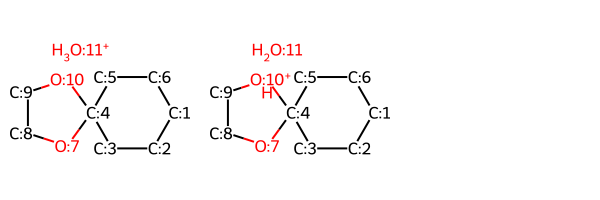

In [15]:
sm_list = []
prod_list = []
for rxn in cc_rxns:
    sm_list.append(Chem.MolFromSmiles(rxn.split('>>')[0]))
    prod_list.append(Chem.MolFromSmiles(rxn.split('>>')[1]))

idx = 90

sm = sm_list[idx]
prod = prod_list[idx]

Chem.SanitizeMol(sm)
Chem.SanitizeMol(prod)
Chem.Draw.MolsToGridImage([sm, prod])

In [16]:
sm_smiles = Chem.MolToSmiles(sm)
prod_smiles = Chem.MolToSmiles(prod)
output = execute_step(sm_smiles, True, True, None, False)
n_output = len(output[0])
smiles_list = []
success_list = []
for i in range(n_output):
    smiles = Chem.MolToSmiles(output[0][i])
    smiles_list.append(smiles)
    fp = make_fingerprint(output[0][i], output[1][i])
    pred = clf.predict(np.array(fp).reshape(1, -1))
    if pred[0] == 1:
        success_list.append(smiles)

if prod_smiles in smiles_list:
    print("Success")
if prod_smiles in success_list:
    print("Double success")

    

Success
Double success


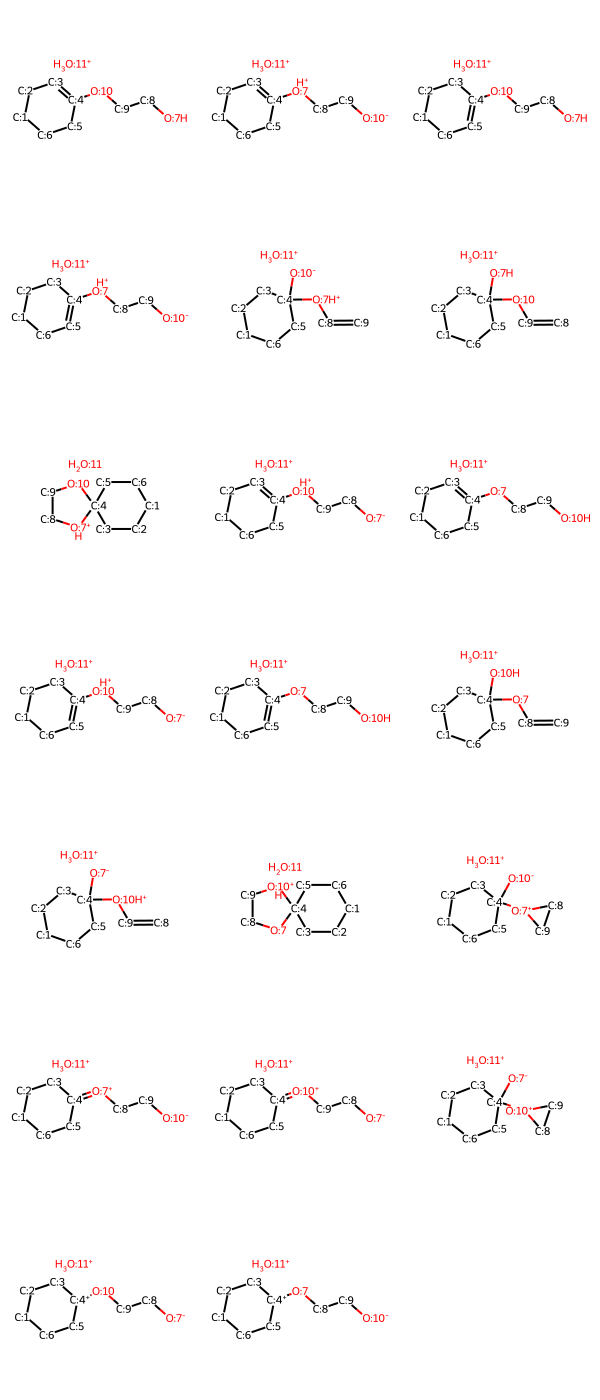

In [17]:
Chem.Draw.MolsToGridImage(output[0])

In [18]:
successes = []
low_successes = []
failures = []
for rxn in cc_rxns:
    sm = Chem.MolFromSmiles(rxn.split('>>')[0])
    prod = Chem.MolFromSmiles(rxn.split('>>')[1])
    for a in sm.GetAtoms():
        a.SetAtomMapNum(0)
    for a in prod.GetAtoms():
        a.SetAtomMapNum(0)
    Chem.RemoveStereochemistry(sm)
    Chem.RemoveStereochemistry(prod)
    prod_smiles = Chem.MolToSmiles(prod)
    sm_smiles = Chem.MolToSmiles(sm)
    prod_smiles = Chem.MolToSmiles(prod)
    print(sm_smiles)
    try:
        output = execute_step(sm_smiles, True, True, None, False)
    except Exception as e:
        print(f"Error processing reaction {rxn}: {e}")
        continue
    n_output = len(output[0])
    smiles_list = []
    success_list = []
    for i in range(n_output):
        Chem.SanitizeMol(output[0][i])
        smiles = Chem.MolToSmiles(output[0][i])
        smiles_list.append(smiles)
        fp = make_fingerprint(output[0][i], output[1][i])
        pred = clf.predict(np.array(fp).reshape(1, -1))
        if pred[0] == 1:
            success_list.append(smiles)

    if prod_smiles in smiles_list:
        low_successes.append(rxn)
    else:
        failures.append(rxn)
    if prod_smiles in success_list:
        successes.append(rxn)
    

CC(C)([O-])C#N.[OH3+]
CC(=O)C(C)C.[BH4-]
CCCCC(C)[O-].Cl
CC(=O)c1ccccc1.O
CC([O-])([OH2+])c1ccccc1
CC([O-])([OH2+])c1ccccc1
CCC(C)=[OH+].CCO
CCC(C)=[OH+].CCO
CC[O-].O=Cc1ccccc1
COC(C)(C)[OH2+]
COC(C)(C)[OH2+]
CO.C[O+]=C(C)C
CC(=O)Cl.CC[O-]
CCOC(C)([O-])Cl
CC(C)[N-]C(C)C.CCC(C)=O
CC(C)[N-]C(C)C.CCC(C)=O
CCCC[N+](=O)[O-].CC[O-]
CC(C)(C)[O-].CCC(=O)CC(C)=O
CC(C)(C)[O-].CCC(=O)CC(C)=O
CC(C)(C)[O-].CCC(=O)CC(C)=O
CC(C)(C)[O-].CCC(=O)CC(C)=O
COC(N)([O-])c1ccccc1
CCC[OH2+].[Br-]
CCC[OH2+].[Br-]
CC([O-])=CC(O)c1cccc(C)c1
C=C(C)CCC=O.[C-]#N
C[O+]=C1C=C2CCCCC2CC1.C[O-]
C[O+]=C1C=C2CCCCC2CC1.C[O-]
C=C(C)[O-].O=Cc1ccccc1
C=CC(C)=O.CC[O-]
C=CC(C)=O.CC[O-]
CC(=O)c1ccccc1.[BH3-]OC(C)C


[15:37:05] 

****
Invariant Violation

Violation occurred on line 341 in file /project/build/temp.linux-x86_64-cpython-313/rdkit/Code/GraphMol/Matrices.cpp
Failed Expression: aid1 != aid2
----------
Stacktrace:
----------
****



Error in calculating shortest path
CC(=O)CC(O)c1ccccc1.[OH-]
CC(=O)CC(O)c1ccccc1.[OH-]
CC(=O)O.CNC
CC1(O)CCCCC1.[OH3+]
CC1([OH2+])CCCCC1
CCC(F)Br.[OH-]
CCOCCl
C[O-].O=C(CCl)c1ccccc1
C[O-].O=C(CCl)c1ccccc1
C[O-].O=C(CCl)c1ccccc1
CC[S+](Cc1ccccc1)Cc1ccccc1.[C-]#N
Cc1ccc(S(=O)(=O)Cl)cc1.OCC1C=CCC1
Error processing reaction [C:1]([c:2]1[c:3]([H:22])[c:4]([H:23])[c:5]([S:6](=[O:7])(=[O:8])[Cl:18])[c:16]([H:24])[c:17]1[H:25])([H:19])([H:20])[H:21].[O:9]([C:10]([C:11]1([H:29])[C:12]([H:30])=[C:13]([H:31])[C:14]([H:32])([H:33])[C:15]1([H:34])[H:35])([H:27])[H:28])[H:26]>>[C:1]([c:2]1[c:3]([H:22])[c:4]([H:23])[c:5]([S:6](=[O:7])(=[O:8])[O+:9]([C:10]([C:11]2([H:29])[C:12]([H:30])=[C:13]([H:31])[C:14]([H:32])([H:33])[C:15]2([H:34])[H:35])([H:27])[H:28])[H:26])[c:16]([H:24])[c:17]1[H:25])([H:19])([H:20])[H:21].[Cl-:18]: Explicit valence for atom # 5 S, 7, is greater than permitted
C[OH+]c1ccccc1.[I-]


[15:37:40] Explicit valence for atom # 5 S, 7, is greater than permitted


C[OH+]c1ccccc1.[I-]
CC1CO1.CCNC
B.CCC=C(C)c1ccccc1
BrBr.C=Cc1ccc(OC)cc1
ClC1CCCOC1Cl
[S-]c1ccccc1.c1ccc(C[S+](c2ccccc2)c2ccccc2)cc1
CC(=O)CCl.C[O-]
CC(=O)CCl.C[O-]
CC(=O)CCl.C[O-]
CC(=O)CCl.C[O-]
ClCc1ccccc1.[OH-]
COC(=O)c1ccccc1C[O-]
O.[NH+]#CCc1ccccc1
O.[NH+]#CCc1ccccc1
CC(C)(C)Br
CC(C)(C)[O-].C[C+](C)C
CCCN(C)C.CI
C[N+](C)(C)CCC1OCCO1.[OH-]
C[N+](C)(C)CCC1OCCO1.[OH-]
C[N+](C)(C)CCC1OCCO1.[OH-]
Br.C=C(C)CC
Br.CC=Cc1ccccc1
BrBr.C1=CCCC1
C1CC2[Br+]C2C1.[Br-]
CC=CCC.O=C(OO)c1ccccc1
B.C=C1CCCCC1
CCBr.CC[O-]
CC(C)Br.CC[O-]
CC(C)Br.CC[O-]
CCCBr.CC[O-]
CCCBr.CC[O-]
CC[O-].ClC(=Cc1ccccc1)c1ccccc1
C1CO1.[C-]#Cc1ccccc1
CC1CCC[OH+]1.[Cl-]
C1CC2(CCO1)CO2.C[N-]C
C1CC2(CCO1)CO2.C[N-]C
C1CC2(CCO1)CO2.C[N-]C
C=CC1CCCC1[O-].CCBr
C1CNCCC2[Br+]C2C1
CC(=O)O.[CH+]1CCCCC1
C[N+](C)(C)CCC1=CC=CC1.[OH-]
C[N+](C)(C)CCC1=CC=CC1.[OH-]
C[N+](C)(C)CCC1=CC=CC1.[OH-]
CC1CC=CC1.O=C(OO)c1cccc(Cl)c1
C=CC1CCCC1[O-].[OH3+]
C1CCC2(CC1)OCCO2.[OH3+]
O.OCC[O+]=C1CCCCC1
CC(C)(C)Br.CC[O-]
CN1C(=O)c2ccccc2C1=O.C[O-]
c1ccc(C2OC

[15:40:39] Explicit valence for atom # 3 S, 7, is greater than permitted


C=CCBr.[O-]C1CCCC1
Br.CC(C)=Cc1ccccc1
Br.CC(C)=Cc1ccccc1
CC(C)I.CC[O-]
CCBr.CCN
CC1(O)C=CC=CC1.[OH3+]
CC1([OH2+])C=CC=CC1
O.[NH+]#CCc1ccccc1
O.[NH+]#CCc1ccccc1
CC1CC[OH+]C1.CC[O-]
CC1CC[OH+]C1.CC[O-]
CC(C)OCBr
CC[O-].O=CCCl
CC[O-].O=CCCl
CC[O-].O=CCCl
CC(C)([O-])CCl
C[NH-].Cc1cccc(CCl)c1
[NH3+]C(CCC[O-])c1ccccc1
CCC(C)(C)Cl.CC[O-]
CCC(C)(C)Cl.CC[O-]
CC[O-].COCC[N+](C)(C)C
CC[O-].COCC[N+](C)(C)C
CC[O-].COCC[N+](C)(C)C
BrBr.C=Cc1ccccc1
O=Cc1ccccc1.[C-]#N
CCC([O-])(Cl)OC
CC(C)C[OH2+].[C-]#N
CC(C)C[OH2+].[C-]#N
C=C([O-])CC.O=Cc1ccccc1
COC(C)(C)[O-]
CCC(C)(C)[O-].[OH3+]
C[N-]C(=O)CCC(C)CBr


In [20]:
len(successes)

68

In [21]:
len(low_successes)

131

In [22]:
len(failures)

14

In [23]:
len(cc_rxns)

147

In [30]:
accounted_for = 0
unaccounted_for = []
unaccounted_for_prod =[]
for idx in range(len(failures)):
    smiles = str(failures[idx]).split('>>')
    sm = Chem.MolFromSmiles(smiles[0])
    for a in sm.GetAtoms():
        a.SetAtomMapNum(0)
    sm_smiles = Chem.MolToSmiles(sm)
    prod = Chem.MolFromSmiles(smiles[1])
    for a in prod.GetAtoms():
        a.SetAtomMapNum(0)
    Chem.RemoveStereochemistry(prod)
    prod_smiles = Chem.MolToSmiles(prod)
    output = execute_step(sm_smiles, True, True, None, False)
    n_output = len(output[0])
    smiles_list = []
    found = False
    for i in range(n_output):
        Chem.SanitizeMol(output[0][i])
        if output[0][i].HasSubstructMatch(keto_enol) or output[0][i].HasSubstructMatch(double_bond) or output[0][i].HasSubstructMatch(hydroboration):
            accounted_for += 1
            found = True
            break
        smiles_out = Chem.MolToSmiles(output[0][i])
        smiles_list.append(smiles_out)
        #fp = make_fingerprint(output[0][i], output[1][i])
        #pred = clf.predict(np.array(fp).reshape(1, -1))
    if not found:
        unaccounted_for.append(sm)
        unaccounted_for_prod.append(prod)
print(accounted_for)
#print(smiles_list[9])
#Chem.Draw.MolsToGridImage([sm, prod]+   output[0])

13


In [29]:
unaccounted_for[2]

IndexError: list index out of range

In [25]:
Chem.MolToSmiles(unaccounted_for_prod[1])

NameError: name 'unaccounted_for_prod' is not defined

SMARTS matching to deal with annoying cases

In [26]:
keto_enol = Chem.MolFromSmarts('[O,N,S;!-]=[*][C-]')
double_bond = Chem.MolFromSmarts('[C+][*-]')
hydroboration = Chem.MolFromSmarts('[C+]C[B-]')

In [27]:
for failure in failures:
    sm = Chem.MolFromSmiles(failure.split('>>')[0])
    prod = Chem.MolFromSmiles(failure.split('>>')[1])
    if sm.HasSubstructMatch(keto_enol) or sm.HasSubstructMatch(double_bond) or sm.HasSubstructMatch(hydroboration):
        print(failure)
        print(sm.HasSubstructMatch(keto_enol))
        print(sm.HasSubstructMatch(double_bond))
        print(sm.HasSubstructMatch(hydroboration))
        print("")
